# Compréhensibilité des fiches services, évaluée par un LLM

Ce carnet présente les résultats de l'exploration décrite dans [spec.md](spec.md) et [plan.md](plan.md) : un modèle de langage lit des fiches services du point de vue d'une personne bénéficiaire, sans connaissance du vocabulaire administratif ou du travail social, et note leur compréhensibilité de 1 à 5.

Il lit uniquement les fichiers produits par les scripts (`sample.parquet`, `scores.parquet`, `examples.parquet`) et ne fait aucun appel à l'API.

Pour le réexécuter :

```
uv run --with jupyter,nbconvert,ipykernel,duckdb,pandas,matplotlib,scipy,scikit-learn \
  jupyter nbconvert --to notebook --execute --inplace results.ipynb
```

In [1]:
import textwrap

import duckdb
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score, confusion_matrix

from analyse import AUDIENCES, LEVELS, distribution_query

# reference palette (dataviz skill), light mode
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
# ordinal ramp for score levels 1 -> 5 (blue 250, 350, 450, 550, 650)
LEVEL_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
LEVEL_INK = [INK, INK, "#ffffff", "#ffffff", "#ffffff"]
# full sequential ramp for the heatmap
SEQUENTIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
# categorical slots 1-4
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
CATEGORICAL_INK = ["#ffffff", "#ffffff", "#ffffff", INK]

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.size": 9,
    "text.color": INK,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.edgecolor": BASELINE,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY,
    "ytick.labelcolor": INK_SECONDARY,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)

con = duckdb.connect()
con.execute("""
    create table scores as
    select r.card_idx, r.run, r.score, r.audience, r.justification, r.model, r.error,
           s.id, s.source, s.n_services, s.score_qualite, s.description_length,
           s.nom, s.description
    from 'scores.parquet' r
    join 'sample.parquet' s using (card_idx)
""")
# main score: run 1
con.execute("create view main as select * from scores where run = 1 and score is not null")


def q(query: str) -> pd.DataFrame:
    return con.sql(query).df()

In [2]:
meta = q("""
    select any_value(model) as model, count(distinct card_idx) as cards, count(distinct run) as runs,
           count(*) as requests, count(*) - count(score) as failures
    from scores
""").iloc[0]
display(Markdown(f"""
**Juge** : `{meta.model}` (effort `medium`), via l'API Batches.
**Échantillon** : {meta.cards} fiches distinctes, {meta.runs} passages, {meta.requests} requêtes, {meta.failures} échec(s).

Échelle (du point de vue de la personne bénéficiaire, quel que soit le public visé) :

| Note | Sens |
|---|---|
| 1 | incompréhensible : jargon, sigles non expliqués, ou texte qui ne dit pas ce qu'est le service ou ne correspond pas à son nom |
| 2 | difficile à comprendre, le lecteur n'en retire qu'une idée vague |
| 3 | compréhensible avec effort, un peu de jargon ou une structure confuse |
| 4 | clair, difficultés mineures |
| 5 | immédiatement clair, langage simple |

Le juge indique aussi à qui la fiche semble s'adresser : `beneficiaire`, `professionnel`, `employeur` ou `indetermine`.
Seul ce qui est écrit est noté : une rubrique absente n'est pas pénalisée (la complétude relève du `score_qualite`).
"""))


**Juge** : `claude-opus-5-5` (effort `medium`), via l'API Batches.
**Échantillon** : 313 fiches distinctes, 2 passages, 626 requêtes, 0 échec(s).

Échelle (du point de vue de la personne bénéficiaire, quel que soit le public visé) :

| Note | Sens |
|---|---|
| 1 | incompréhensible : jargon, sigles non expliqués, ou texte qui ne dit pas ce qu'est le service ou ne correspond pas à son nom |
| 2 | difficile à comprendre, le lecteur n'en retire qu'une idée vague |
| 3 | compréhensible avec effort, un peu de jargon ou une structure confuse |
| 4 | clair, difficultés mineures |
| 5 | immédiatement clair, langage simple |

Le juge indique aussi à qui la fiche semble s'adresser : `beneficiaire`, `professionnel`, `employeur` ou `indetermine`.
Seul ce qui est écrit est noté : une rubrique absente n'est pas pénalisée (la complétude relève du `score_qualite`).


## 1. Échantillon

L'unité est la **fiche distincte** : beaucoup de services partagent exactement le même texte. On tire 20 fiches distinctes par source, 50 pour dora et soliguide (toutes quand il y en a moins), avec une graine fixe. Chaque fiche garde `n_services`, le nombre de services de sa source qui partagent ce texte.

In [3]:
q("""
    with totals as (select source, count(*) as services_source from 'services.parquet' group by source)
    select source,
           count(*) as fiches_tirees,
           sum(n_services)::bigint as services_couverts,
           any_value(services_source) as services_source,
           round(100 * sum(n_services) / any_value(services_source), 1) as pct_couvert
    from 'sample.parquet' join totals using (source)
    group by source
    order by source
""")

,source,fiches_tirees,services_couverts,services_source,pct_couvert
0,action-logement,20,2320,2552,90.9
1,agefiph,20,400,760,52.6
2,carif-oref,20,25,6381,0.4
3,cd35,20,20,778,2.6
4,dora,50,93,22721,0.4
5,finess,2,2048,2048,100.0
6,france-travail,11,9735,9735,100.0
7,fredo,20,21,3368,0.6
8,ma-boussole-aidants,20,14199,14309,99.2
9,mediation-numerique,20,20,16597,0.1


finess et france-travail n'ont que 2 et 11 fiches distinctes : l'échantillon les couvre entièrement. ma-boussole-aidants et action-logement ont peu de fiches distinctes, chacune partagée par beaucoup de services.

## 2. Fiabilité du juge

Le juge a noté tout l'échantillon deux fois. Sans jeu de référence annoté par des humains, la cohérence entre les deux passages est le seul contrôle : elle mesure la stabilité de la note, pas sa justesse.

In [4]:
pairs = q("""
    select r1.card_idx, r1.score as score_1, r2.score as score_2,
           r1.audience as audience_1, r2.audience as audience_2
    from scores r1 join scores r2 using (card_idx)
    where r1.run = 1 and r2.run = 2 and r1.score is not null and r2.score is not null
""")
pd.DataFrame({
    "indicateur": [
        "fiches notées deux fois",
        "accord exact",
        "accord à 1 point près",
        "kappa pondéré quadratique",
        "accord sur le public visé",
    ],
    "valeur": [
        f"{len(pairs)}",
        f"{(pairs.score_1 == pairs.score_2).mean():.1%}",
        f"{((pairs.score_1 - pairs.score_2).abs() <= 1).mean():.1%}",
        f"{cohen_kappa_score(pairs.score_1, pairs.score_2, weights='quadratic', labels=LEVELS):.3f}",
        f"{(pairs.audience_1 == pairs.audience_2).mean():.1%}",
    ],
}).set_index("indicateur")

,valeur
indicateur,
fiches notées deux fois,313
accord exact,93.3%
accord à 1 point près,100.0%
kappa pondéré quadratique,0.946
accord sur le public visé,95.2%


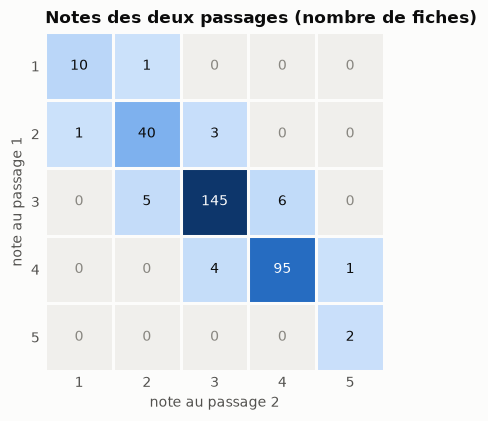

In [5]:
matrix = confusion_matrix(pairs.score_1, pairs.score_2, labels=LEVELS)
cmap = mpl.colors.LinearSegmentedColormap.from_list("blues", SEQUENTIAL)

fig, ax = plt.subplots(figsize=(4.6, 4.0))
cmap.set_bad("#f0efec")  # empty cells recede to neutral gray
ax.imshow(np.ma.masked_equal(matrix, 0), cmap=cmap, vmin=0, vmax=matrix.max())
# 2px surface gap between cells
ax.set_xticks(np.arange(-0.5, 5, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
for i in range(5):
    for j in range(5):
        value = matrix[i, j]
        ink = "#ffffff" if value > matrix.max() * 0.45 else INK
        ax.text(j, i, str(value), ha="center", va="center", color=ink if value else INK_MUTED, fontsize=9)
ax.set_xticks(range(5), LEVELS)
ax.set_yticks(range(5), LEVELS)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel("note au passage 2")
ax.set_ylabel("note au passage 1")
ax.set_title("Notes des deux passages (nombre de fiches)")
plt.show()

Presque tous les désaccords portent sur un seul point, surtout entre 2, 3 et 4. La note est assez stable pour comparer les sources ; la suite utilise le **passage 1**.

## 3. Comparaison par source

`s1` à `s5` sont les parts de chaque note, `moyenne` et `mediane` portent sur les fiches. Avec 20 fiches par source (50 pour dora et soliguide), ces chiffres sont **indicatifs** : un écart de quelques dixièmes de point entre deux sources n'est pas significatif.

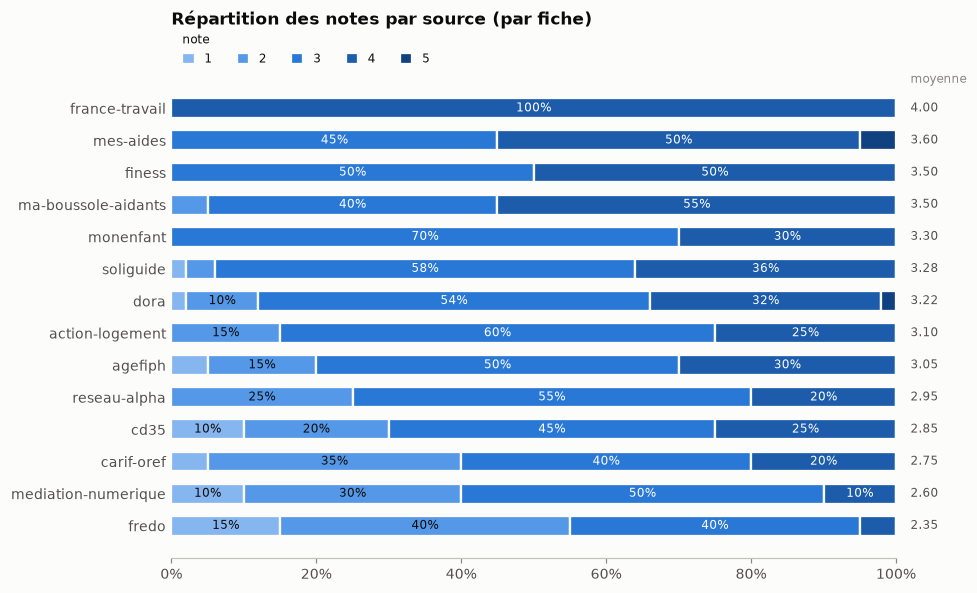

,fiches,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,
france-travail,11,0.00,0.00,0.00,1.00,0.00,4.00,4
mes-aides,20,0.00,0.00,0.45,0.50,0.05,3.60,4
finess,2,0.00,0.00,0.50,0.50,0.00,3.50,3
ma-boussole-aidants,20,0.00,0.05,0.40,0.55,0.00,3.50,4
monenfant,20,0.00,0.00,0.70,0.30,0.00,3.30,3
soliguide,50,0.02,0.04,0.58,0.36,0.00,3.28,3
dora,50,0.02,0.10,0.54,0.32,0.02,3.22,3
action-logement,20,0.00,0.15,0.60,0.25,0.00,3.10,3
agefiph,20,0.05,0.15,0.50,0.30,0.00,3.05,3


In [6]:
def by_source(where: str = "true", weight: str = "1") -> pd.DataFrame:
    df = q(distribution_query(where=where, weight=weight))
    return df.rename(columns={"cards": "fiches", "weight": "poids", "mean": "moyenne", "median": "mediane"})


def plot_levels(df: pd.DataFrame, title: str) -> None:
    """100% stacked horizontal bars of score levels, sources ordered by mean."""
    df = df.sort_values("moyenne").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(df) + 1.2))
    left = np.zeros(len(df))
    for level, color, ink in zip(LEVELS, LEVEL_COLORS, LEVEL_INK):
        share = df[f"s{level}"].to_numpy()
        ax.barh(df.source, share, left=left, height=0.62, color=color,
                edgecolor=SURFACE, linewidth=1.5, label=f"{level}")
        for y, (x, s) in enumerate(zip(left, share)):
            if s >= 0.1:
                ax.text(x + s / 2, y, f"{s:.0%}", ha="center", va="center", color=ink, fontsize=8)
        left += share
    for y, m in enumerate(df.moyenne):
        ax.text(1.02, y, f"{m:.2f}", va="center", color=INK_SECONDARY, fontsize=8)
    ax.text(1.02, len(df) - 0.3, "moyenne", va="bottom", color=INK_MUTED, fontsize=8)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=1))
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.legend(title="note", ncols=5, loc="lower left", bbox_to_anchor=(0, 1.0),
              handlelength=1, handleheight=1, alignment="left", title_fontsize=8, fontsize=8)
    ax.set_title(title, pad=34)
    plt.show()


per_card = by_source()
plot_levels(per_card, "Répartition des notes par source (par fiche)")
per_card.drop(columns="poids").set_index("source")

### Pondéré par le nombre de services

Une fiche partagée par 885 services pèse 885 fois plus qu'une fiche unique. La pondération montre ce que voit un utilisateur qui parcourt les services plutôt que les textes distincts.

In [7]:
weighted = by_source(weight="n_services")
weighted.set_index("source")

,fiches,poids,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,,
france-travail,11,9735,0.00,0.00,0.00,1.00,0.00,4.00,4
finess,2,2048,0.00,0.00,0.05,0.95,0.00,3.95,4
mes-aides,20,20,0.00,0.00,0.45,0.50,0.05,3.60,4
monenfant,20,20,0.00,0.00,0.70,0.30,0.00,3.30,3
soliguide,50,57,0.02,0.04,0.60,0.35,0.00,3.28,3
dora,50,93,0.01,0.05,0.67,0.25,0.02,3.22,3
action-logement,20,2320,0.00,0.15,0.60,0.25,0.00,3.10,3
agefiph,20,400,0.05,0.15,0.50,0.30,0.00,3.05,3
ma-boussole-aidants,20,14199,0.00,0.00,1.00,0.00,0.00,3.00,3


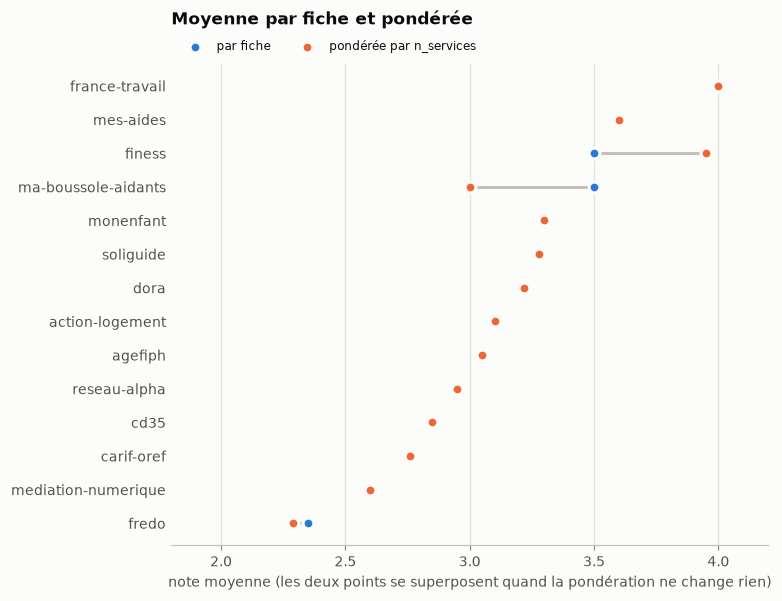

In [8]:
compare = per_card[["source", "moyenne"]].merge(
    weighted[["source", "moyenne"]], on="source", suffixes=("_fiche", "_pondere")
).sort_values("moyenne_fiche").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 0.32 * len(compare) + 1.2))
y = np.arange(len(compare))
ax.hlines(y, compare.moyenne_fiche, compare.moyenne_pondere, color=BASELINE, linewidth=2)
ax.scatter(compare.moyenne_fiche, y, s=50, color=CATEGORICAL[0], edgecolor=SURFACE, linewidth=2, zorder=3, label="par fiche")
ax.scatter(compare.moyenne_pondere, y, s=50, color=CATEGORICAL[1], edgecolor=SURFACE, linewidth=2, zorder=3, label="pondérée par n_services")
ax.set_yticks(y, compare.source)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlim(1.8, 4.2)
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlabel("note moyenne (les deux points se superposent quand la pondération ne change rien)")
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
ax.set_title("Moyenne par fiche et pondérée", pad=26)
plt.show()

In [9]:
ft = q("""
    select count(*) as n, min(n_services) as min_n, max(n_services) as max_n
    from main where source = 'france-travail'
""").iloc[0]
cmp = compare.set_index("source")
fi, mba = cmp.loc["finess"], cmp.loc["ma-boussole-aidants"]
display(Markdown(
    f"La pondération change surtout finess ({fi.moyenne_fiche:.2f} → {fi.moyenne_pondere:.2f}) et "
    f"ma-boussole-aidants ({mba.moyenne_fiche:.2f} → {mba.moyenne_pondere:.2f}). "
    f"Elle ne change rien pour france-travail : ses {ft.n} fiches sont partagées chacune par "
    f"{ft.min_n if ft.min_n == ft.max_n else f'{ft.min_n} à {ft.max_n}'} services."
))

La pondération change surtout finess (3.50 → 3.95) et ma-boussole-aidants (3.50 → 3.00). Elle ne change rien pour france-travail : ses 11 fiches sont partagées chacune par 885 services.

### Fiches rédigées pour les bénéficiaires

Certaines fiches s'adressent à des professionnels ou à des employeurs ; leur note reste donnée du point de vue de la personne bénéficiaire. En se limitant aux fiches que le juge considère écrites pour les bénéficiaires :

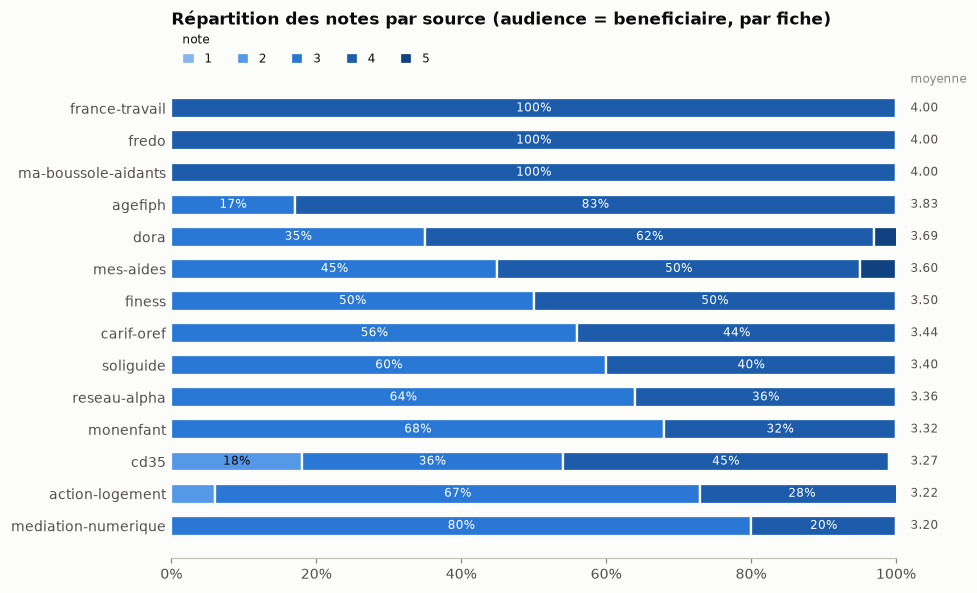

,fiches,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,
france-travail,11,0.0,0.00,0.00,1.00,0.00,4.00,4
fredo,1,0.0,0.00,0.00,1.00,0.00,4.00,4
ma-boussole-aidants,4,0.0,0.00,0.00,1.00,0.00,4.00,4
agefiph,6,0.0,0.00,0.17,0.83,0.00,3.83,4
dora,26,0.0,0.00,0.35,0.62,0.04,3.69,4
mes-aides,20,0.0,0.00,0.45,0.50,0.05,3.60,4
finess,2,0.0,0.00,0.50,0.50,0.00,3.50,3
carif-oref,9,0.0,0.00,0.56,0.44,0.00,3.44,3
soliguide,42,0.0,0.00,0.60,0.40,0.00,3.40,3


In [10]:
beneficiaire = by_source(where="audience = 'beneficiaire'")
plot_levels(beneficiaire, "Répartition des notes par source (audience = beneficiaire, par fiche)")
beneficiaire.drop(columns="poids").set_index("source")

In [11]:
by_source(where="audience = 'beneficiaire'", weight="n_services").set_index("source")

,fiches,poids,s1,s2,s3,s4,s5,moyenne,mediane
source,,,,,,,,,
france-travail,11,9735,0.0,0.00,0.00,1.00,0.00,4.00,4
fredo,1,1,0.0,0.00,0.00,1.00,0.00,4.00,4
ma-boussole-aidants,4,24,0.0,0.00,0.00,1.00,0.00,4.00,4
finess,2,2048,0.0,0.00,0.05,0.95,0.00,3.95,4
agefiph,6,120,0.0,0.00,0.17,0.83,0.00,3.83,4
mes-aides,20,20,0.0,0.00,0.45,0.50,0.05,3.60,4
carif-oref,9,12,0.0,0.00,0.58,0.42,0.00,3.42,3
dora,26,69,0.0,0.00,0.64,0.33,0.03,3.39,3
soliguide,42,49,0.0,0.00,0.61,0.39,0.00,3.39,3


## 4. Public visé

Part des fiches de chaque source selon le public auquel elles semblent s'adresser.

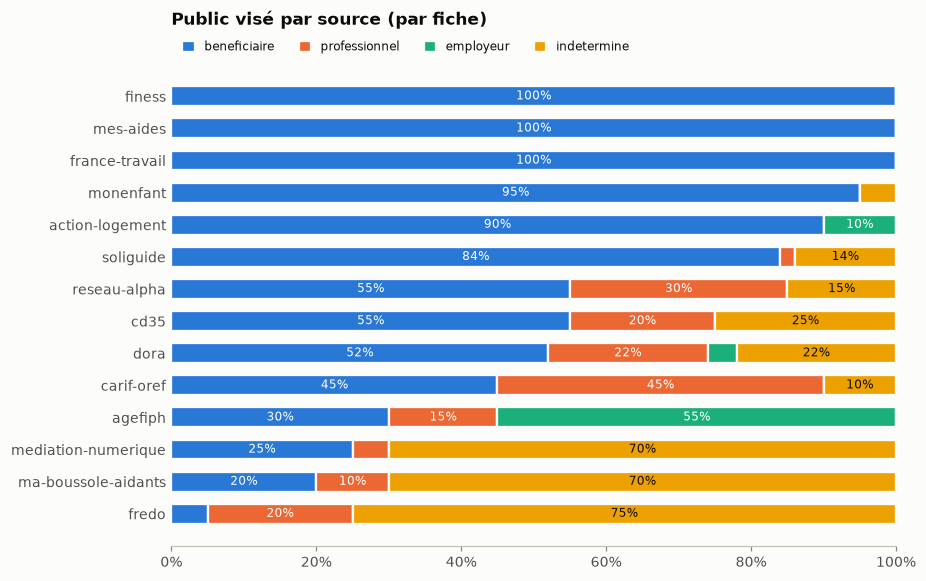

,fiches,beneficiaire,professionnel,employeur,indetermine
source,,,,,
fredo,20,0.05,0.20,0.00,0.75
ma-boussole-aidants,20,0.20,0.10,0.00,0.70
mediation-numerique,20,0.25,0.05,0.00,0.70
agefiph,20,0.30,0.15,0.55,0.00
carif-oref,20,0.45,0.45,0.00,0.10
dora,50,0.52,0.22,0.04,0.22
cd35,20,0.55,0.20,0.00,0.25
reseau-alpha,20,0.55,0.30,0.00,0.15
soliguide,50,0.84,0.02,0.00,0.14


In [12]:
aud = q(f"""
    select source, count(*) as fiches,
           {", ".join(f"avg((audience = '{a}')::int) as {a}" for a in AUDIENCES)}
    from main group by source
""").sort_values("beneficiaire").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(aud) + 1.2))
left = np.zeros(len(aud))
for a, color, ink in zip(AUDIENCES, CATEGORICAL, CATEGORICAL_INK):
    share = aud[a].to_numpy()
    ax.barh(aud.source, share, left=left, height=0.62, color=color, edgecolor=SURFACE, linewidth=1.5, label=a)
    for y, (x, s) in enumerate(zip(left, share)):
        if s >= 0.1:
            ax.text(x + s / 2, y, f"{s:.0%}", ha="center", va="center", color=ink, fontsize=8)
    left += share
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(xmax=1))
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(ncols=4, loc="lower left", bbox_to_anchor=(0, 1.0), handlelength=1, handleheight=1, fontsize=8)
ax.set_title("Public visé par source (par fiche)", pad=26)
plt.show()
aud.set_index("source").round(2)

agefiph s'adresse surtout aux employeurs, et près de la moitié des fiches carif-oref semblent écrites pour des professionnels. Les fiches `indetermine`, nombreuses chez fredo, mediation-numerique et ma-boussole-aidants, sont souvent des textes très courts ou génériques.

## 5. Corrélations

Corrélation de Spearman entre la note (passage 1) et deux grandeurs connues pour chaque fiche : le `score_qualite` de son service représentatif (qui mesure surtout la complétude) et la longueur de la description.

In [13]:
main = q("select score, score_qualite, description_length from main")
rows = []
for col in ["score_qualite", "description_length"]:
    sub = main.dropna(subset=[col])
    rho, p_value = spearmanr(sub.score, sub[col])
    rows.append({"variable": col, "rho": round(rho, 3), "p": f"{p_value:.3g}", "n": len(sub)})
pd.DataFrame(rows).set_index("variable")

,rho,p,n
variable,,,
score_qualite,0.128,0.0231,313
description_length,-0.084,0.136,313


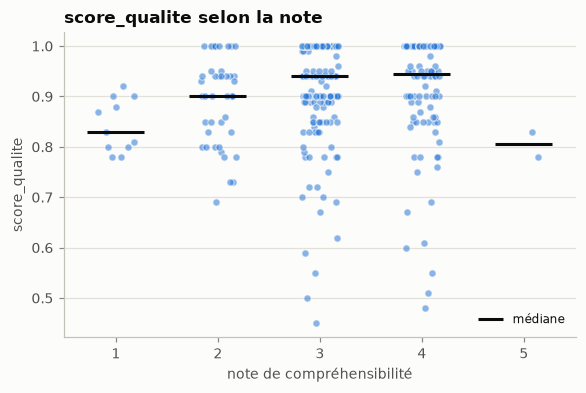

In [14]:
rng = np.random.default_rng(seed=0)
fig, ax = plt.subplots(figsize=(6, 3.6))
jitter = rng.uniform(-0.18, 0.18, size=len(main))
ax.scatter(main.score + jitter, main.score_qualite, s=22, color=CATEGORICAL[0], alpha=0.55, edgecolor=SURFACE, linewidth=0.8)
medians = main.groupby("score").score_qualite.median()
ax.hlines(medians.values, medians.index - 0.28, medians.index + 0.28, color=INK, linewidth=2, label="médiane")
ax.set_xticks(LEVELS)
ax.set_xlabel("note de compréhensibilité")
ax.set_ylabel("score_qualite")
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.legend(loc="lower right", fontsize=8)
ax.set_title("score_qualite selon la note")
plt.show()

La note de compréhensibilité est faiblement liée au `score_qualite` et pas à la longueur : les deux mesurent des choses différentes, la compréhensibilité apporte une information que le `score_qualite` ne donne pas.

## 6. Exemples

Pour chaque note, jusqu'à 5 fiches de sources différentes, avec la justification du juge (`examples.parquet`). Descriptions tronquées.

In [15]:
def clean(text: str, width: int) -> str:
    text = " ".join(text.replace("\\n", " ").split())
    text = text.replace("#", "").replace("*", "").replace("|", "/")
    return textwrap.shorten(text, width=width, placeholder=" …")


examples = q("select * from 'examples.parquet' order by score, source")
for score, group in examples.groupby("score"):
    lines = [f"### Note {score}"]
    for row in group.itertuples():
        lines.append(
            f"**{clean(row.nom, 120)}** · {row.source} · public : {row.audience}\n\n"
            f"> {clean(row.description, 400)}\n\n"
            f"*Juge* : {row.justification}\n"
        )
    display(Markdown("\n".join(lines)))

### Note 1
**Evaluation finale - Socle de connaissances et de compétences professionnelles numérique (CléA Numérique)** · carif-oref · public : indetermine

> Objectif de la formation Validation des compétences Contenu de la formation 1 Evaluation finale

*Juge* : Le sigle « CléA Numérique » et l'expression « socle de connaissances et de compétences professionnelles » ne sont pas expliqués, et le texte (« Validation des compétences », « 1 Evaluation finale ») ne dit pas concrètement ce qui est proposé ni à quoi sert ce certificat.

**Soins infirmiers à domicile** · cd35 · public : professionnel

> Les SESSAD apportent aux familles conseils et accompagnement, ils favorisent l'intégration scolaire et l'acquisition de l'autonomie grâce à des moyens médicaux, paramédicaux, psychosociaux, éducatifs et pédagogiques adaptés. Les interventions ont lieu dans les différents lieux de vie et d’activité de l’enfant ou de l’adolescent (domicile, crèche, école, centre de vacances…) et dans les locaux du …

*Juge* : Le nom « Soins infirmiers à domicile » ne correspond pas au contenu, qui décrit un SESSAD pour enfants handicapés. Le texte est chargé de sigles (SESSAD expliqué seulement à la fin, CLIS, ULIS jamais expliqués) et de jargon (« moyens paramédicaux, psychosociaux », « dispositif d'intégration collective », « milieu ordinaire »), et les tranches d'âge se contredisent (0-20 ans puis 3-16 ans).

**Employabilité** · dora · public : employeur

> Faciliter votre employabilité en favorisant votre mobilité (travail et logement). Levée d'un frein périphérique (absence de logement) par une orientation partenariale. Talents internationaux est une agence de placement de main-d’œuvre s'investissant:<br> Talents internationaux est spécialisée dans l'accompagnement des entreprises recherchant des profils pénuriques et dans l'accompagnement des …

*Juge* : Le texte est saturé de jargon (« frein périphérique », « orientation partenariale », « profils pénuriques », « métiers en tension », « sourcing proactif », « marque employeur », « marketing RH », sigle EURES non expliqué) et contient une phrase coupée (« s'investissant: »). Le lecteur ne comprend pas concrètement ce qui lui est proposé, et le titre « Employabilité » est lui-même un mot technique.

**Accompagnement dans les démarches** · fredo · public : indetermine

> Apporter une aide alimentaire

*Juge* : La description « Apporter une aide alimentaire » ne correspond pas au nom « Accompagnement dans les démarches », donc le lecteur ne sait pas si on l'aide pour ses démarches ou pour se nourrir. La phrase est aussi trop vague pour dire concrètement ce qui est proposé.

**Psychologie** · soliguide · public : professionnel

> Accompagnement vers les soins somatiques, les soins en addictologie et les besoins en suivi psychologique/psychiatrique Dans une recherche permanente de prévention de la récidive en matière de violences intrafamiliales, le Dispositif d’Accompagnement des Auteurs de Violences IntraFamiliales (DAAVIF) accueille des personnes prévenues ou condamnées à titre définitif, pour des actes de violences …

*Juge* : La fiche accumule des sigles jamais expliqués (SPIP, CPIP, JAP, DDSE, LC, PSE, CCP) et un vocabulaire juridique et médical (« prévenues », « soins somatiques », « addictologie », « article 723-15 », « placement ») incompréhensibles pour le lecteur. De plus, le nom « Psychologie » ne reflète pas vraiment le service, qui est un dispositif judiciaire de suivi des auteurs de violences intrafamiliales.


### Note 2
**Consultation gratuite de notaire** · cd35 · public : indetermine

> La chambre interdépartementale des notaires de la cour d’appel de Rennes regroupe les notaires des Côtes-d’Armor, du Finistère, de l’Ille-et-Vilaine, de la Loire-Atlantique et du Morbihan. Les anciennes chambres des Notaires sont devenues des pôles territoriaux, qui peuvent continuer à recevoir du public. La compétence territoriale de la chambre interdépartementale correspond aux limites des 33 …

*Juge* : La description parle surtout de l'organisation institutionnelle de la chambre des notaires (« compétence territoriale », « ressort », « pôles territoriaux », « déontologie », « études ») et ne mentionne la consultation gratuite, qui est l'objet du service, qu'en dernière phrase, sans dire en quoi elle consiste. Le lecteur n'en retire qu'une idée vague.

**Ecoute / soutien** · fredo · public : indetermine

> Le Service d’accompagnement Médico Social pour Adulte Handicapé est une structure qui propose un accompagne médico social adapté incluant des prestations de soinsIl favorise le maintien ou la restauration de liens familiaux, sociaux, scolaire, universitaire ou professionnels et faciliter l’accès à l’ensemble des services offerts par la collectivité

*Juge* : Le nom « Ecoute / soutien » correspond mal à la description, qui parle d'un service d'accompagnement médico-social pour adultes handicapés. Le texte emploie un vocabulaire administratif (« accompagnement médico social adapté », « prestations de soins », « services offerts par la collectivité ») et contient des fautes (« accompagne », « soinsIl », « faciliter »). Le lecteur n'en retire qu'une idée vague de ce qui est proposé concrètement.

**Démarches complémentaires** · ma-boussole-aidants · public : indetermine

> Interlocuteur de second niveau pour toutes démarches de suivi de dossier (aides financières, congé proche aidant…)

*Juge* : « Interlocuteur de second niveau » est du jargon administratif obscur, et « démarches de suivi de dossier » reste vague : on ne sait pas qui est cet interlocuteur ni ce qu'il fait concrètement. Les exemples (aides financières, congé proche aidant) donnent seulement une idée générale.

**Atelier FLE** · reseau-alpha · public : indetermine

> Devenir autonome au quotidien Objectifs visés : Devenir autonome au quotidien Niveau de langue et de compétences visé par la formation : A2, B1 Pas de places disponibles Étendue de la formation : 14 septembre 2026 - 30 juin 2027

*Juge* : Le sigle « FLE » (français langue étrangère) n'est jamais expliqué, et les niveaux « A2, B1 » ne parlent pas au lecteur ; la condition « Scolarisé (3ans et +) en langue étrangère » est obscure. On devine vaguement qu'il s'agit d'un atelier pour devenir autonome, sans comprendre qu'il s'agit d'apprendre le français.

**Point d’information et d’orientation** · soliguide · public : indetermine

> Connexion à internet, informations administratives La mission de l'association est de créer du lien social entre les habitants du quartier avec des équipements à destination des quartiers défavorisés : épicerie solidaire et boutique solidaire.

*Juge* : La fiche annonce un point d'information mais parle surtout de l'association, de son épicerie et de sa boutique solidaires, sans relier clairement les deux : on ne sait pas exactement ce qui est proposé. Les expressions « reste à vivre », « dossier de commission sur orientation d'un travailleur social » et « plage horaires déterminé avec la structure » relèvent du jargon administratif et restent obscures pour le lecteur.


### Note 3
**Conseil et accompagnement emploi handicap des entreprises** · agefiph · public : employeur

> En fonction des besoins de l'entreprise, l'expert Agefiph : informe l'entreprise sur ses obligations en matière d'emploi de personnes handicapées, les interlocuteurs utiles, les outils et solutions, analyse les besoins et conçoit avec l'entreprise un plan d'action sur-mesure. A cette étape, l'expert Agefiph peut mobiliser un prestataire pour réaliser un "diagnostic action", accompagne …

*Juge* : Le texte est structuré et explique assez simplement le rôle de l'expert (informer, analyser, accompagner l'entreprise), mais le sigle « Agefiph » n'est jamais expliqué et des termes comme « mobiliser un prestataire » ou « diagnostic action » restent flous pour un lecteur non initié.

**Accueil collectif ponctuel : halte garderie - multi accueil** · cd35 · public : indetermine

> Les établissements ou services « multi -accueil » associent différentes formules d’accueil : accueil à temps partiel, accueil ponctuel ou en urgence, ou crèche / halte-garderie et crèche familiales L’objectif des multi-accueil est d’apporter la plus grande souplesse possible des solutions d’accueil qui sont proposées aux parents. En permettant de combiner accueil collectif et accueil familial, …

*Juge* : Le sujet (garde de jeunes enfants avec des formules souples) se devine, mais le texte reste administratif : « formules d’accueil », « accueil collectif et accueil familial », « crèche familiale », « horaires atypiques » ne sont pas expliqués. La partie sur les crèches parentales s’éloigne du nom du service, et la phrase « 16 places, âgés de 2 mois à 3 ans » est confuse.

**Parcours d'insertion socioprofessionnel - Demandeur(se) d'emploi en situation de handicap** · dora · public : indetermine

> Cap emploi informe, conseille et accompagne les personnes en situation de handicap en recherche d’emploi et les employeurs privés et publics. Cap emploi est expert de la relation emploi/handicap. Cap emploi exerce une mission de service public. Il a pour rôle d'informer, conseiller et d'accompagner : les personnes qui ont un handicap reconnu ou en cours de reconnaissance dans : - l’élaboration …

*Juge* : L'idée générale reste compréhensible : Cap emploi accompagne vers l'emploi les personnes handicapées. Mais le texte est lourd de jargon administratif (« adéquation emploi/handicap », « besoin de compensation », « LUA », « obligation d'emploi », « article L. 241-2 du code des pensions militaires », « CDAPH ») et s'adresse aussi aux employeurs, ce qui brouille la lecture.

**Guichet unique d’accès simplifié aux droits et prestations pour les personnes handicapées (MDPH)** · finess · public : beneficiaire

> Les maisons départementales des personnes handicapées (MDPH) sont, dans chaque département, le guichet unique d’accès simplifié aux droits et prestations pour les personnes handicapées (enfants et adultes). La MDPH peut : - vous accueillir vous et votre famille - vous informer - vous aider pour expliquer votre situation et vos besoins - regarder votre dossier de demande d’aide. Beaucoup de …

*Juge* : Le sigle MDPH est expliqué et la liste « vous accueillir, vous informer… » est simple, mais des expressions administratives comme « guichet unique d’accès simplifié aux droits et prestations », « téléservice », « saisie du formulaire » ou « MDPH compétente… résidence principale » demandent un effort. Les « \n » littéraux gênent un peu la lecture.

**Conseil administratif** · soliguide · public : beneficiaire

> Quinze structures France Services sont ouvertes dans le Bas-Rhin (67) Ces structures proposent un accompagnement dans l’utilisation des services en ligne d’administrations publiques partenaires (la CAF, la MSA, l’Assurance Maladie, France Travail (ex-Pôle emploi), la Poste, l’assurance retraite (CNAV), les impôts (DDFIP), le ministère de la justice (accès aux droits), le ministère de l’intérieur …

*Juge* : Le texte indique qu'on peut être aidé pour ses démarches en ligne et utiliser des ordinateurs, mais il accumule des sigles sans les expliquer (CAF, MSA, CNAV, DDFIP). La longue liste entre parenthèses et des formulations comme « administrations publiques partenaires », « permanences dans les espaces » ou « hors démarche droit des étrangers » rendent la lecture laborieuse.


### Note 4
**Accueil collectif permanent : crèche - micro-crèche ...** · cd35 · public : beneficiaire

> Crèche collective privée, conventionnée par la Caisse des Allocations Familiales d'Ille-et-Vilaine. Pour les enfants âgés de 10 mois à 3 ans. Groupe fondé en 2016, en région parisienne qui compte près d'une cinquantaine de crèches et de micro-crèches en Île-de-France et qui se développe actuellement dans le Grand Ouest. Les crèches de Bébés explorateurs sont fondées sur le principe d'autonomie …

*Juge* : La fiche dit clairement qu'il s'agit d'une crèche pour enfants de 10 mois à 3 ans, et la CAF est écrite en toutes lettres. Quelques passages restent peu accessibles : « conventionnée », les références « Montessori et Pikler » non expliquées, et l'historique du groupe, qui n'aide pas le lecteur.

**MOBILITES ACTIVES** · dora · public : beneficiaire

> Accompagnement sur le "savoir" et le "pouvoir" bouger C'est un accompagnement collectif de 5 jours, en petit groupe (5-6 personnes maximum) sur les différentes mobilités : analyse et test des différents modes de transports sur le département, organisation et planification de trajet, atelier sur la confiance en soi… Le but est de connaître tous les différents modes de transports en Tarn et …

*Juge* : La description est claire et concrète : 5 jours en petit groupe pour découvrir et tester les transports du Tarn-et-Garonne (bus, train), apprendre à organiser un trajet et connaître les aides. Quelques difficultés mineures : « carte pastel » n'est pas expliquée, « prescripteur partenaire » relève du jargon, et la liste des attestations (RSA, AAH, Reconnaissance Qualité Travailleur Handicapé) ne dit pas clairement s'il en faut une seule ou toutes.

**Mes démarches en ligne avec France Travail** · france-travail · public : beneficiaire

> Vous avez besoin d’aide pour utiliser votre espace numérique et réaliser vos démarches en ligne avec France Travail ?

*Juge* : La fiche s'adresse directement au lecteur et dit clairement qu'il s'agit d'une aide pour utiliser son espace en ligne France Travail. Petites difficultés : « usagers » et « via le lien fourni » restent un peu flous, car aucun lien n'est donné, et la description est posée sous forme de question sans dire concrètement quelle aide est apportée.

**Réparation, vente et location de voiture, moto, scooter** · mes-aides · public : beneficiaire

> Réparation, vente et location de voiture, moto, scooter à tarif solidaire pour les personnes en difficulté, et selon leur situation.

*Juge* : La fiche est courte et claire : réparation, vente et location de véhicules à prix réduit pour les personnes en difficulté, avec une adhésion annuelle chiffrée. Seul le terme « quotient familial » peut gêner un lecteur non initié, et « selon leur situation » reste un peu flou.

**Aide à la mobilité** · soliguide · public : beneficiaire

> Le conseil en mobilité Bilan, ateliers collectifs, entretiens individuels, orientation. Plateforme mobilité du pays de Lorient Vous êtes en recherche d’emploi ou de formation, vous avez des difficultés à connaître l’ensemble des modes de déplacements disponibles sur votre zone de prospection ? Ti Mouv’ vous propose des accompagnements à la mobilité et développe des solutions de mobilité.

*Juge* : La fiche s'adresse directement au lecteur (« Vous êtes en recherche d'emploi… ») et explique simplement l'aide aux déplacements et la démarche à suivre. Quelques termes restent flous : « zone de prospection », « fiche d'orientation », « référent socio-professionnel », et les services « Déplacement à la demande » et « Location solidaire » sont cités sans être décrits.


### Note 5
**Accueil spontané** · dora · public : beneficiaire

> Se faire aider pour la réalisation d'un CV, d'une candidature et être conseillé dans ses démarches de recherche d'emploi

*Juge* : Le texte est court et en langage simple : on comprend qu'on peut se faire aider pour faire son CV, une candidature et sa recherche d'emploi. Le nom « Accueil spontané » est un peu vague, mais la description l'éclaire suffisamment.

**Bourse au permis de conduire / La Turbie** · mes-aides · public : beneficiaire

> La mairie de la Turbie propose à ses jeunes habitants une bourse au permis de conduire d'un montant de 700€. Montant 700 €

*Juge* : Le texte est simple et direct : la mairie de La Turbie donne 700 € aux jeunes de 17 à 25 ans de la commune pour passer le permis de conduire. Les papiers à fournir sont listés clairement et la démarche (envoyer un mail ou appeler la mairie) est facile à suivre ; seul « avis d'imposition » est un terme un peu administratif, mais il reste courant.


## 7. Comparaison avec un premier passage sur Haiku

Un premier passage a été fait avec `claude-haiku-5-5`, sur 20 fiches par source et avec la même consigne (archivé dans `runs/haiku-5-5_20-per-source/`). Les fiches de ce premier échantillon sont toutes reprises dans l'échantillon actuel ; on compare les notes du passage 1 des deux modèles sur ces fiches communes.

In [16]:
HAIKU_SCORES = "runs/haiku-5-5_20-per-source/scores.parquet"
models = q(f"""
    select h.id, h.source, h.score as haiku, m.score as opus,
           h.audience as audience_haiku, m.audience as audience_opus
    from '{HAIKU_SCORES}' h join main m using (id)
    where h.run = 1 and h.score is not null
""")
pd.DataFrame({
    "indicateur": [
        "fiches communes",
        "accord exact",
        "accord à 1 point près",
        "kappa pondéré quadratique",
        "accord sur le public visé",
        "note moyenne Haiku",
        "note moyenne Opus",
    ],
    "valeur": [
        f"{len(models)}",
        f"{(models.haiku == models.opus).mean():.1%}",
        f"{((models.haiku - models.opus).abs() <= 1).mean():.1%}",
        f"{cohen_kappa_score(models.haiku, models.opus, weights='quadratic', labels=LEVELS):.3f}",
        f"{(models.audience_haiku == models.audience_opus).mean():.1%}",
        f"{models.haiku.mean():.2f}",
        f"{models.opus.mean():.2f}",
    ],
}).set_index("indicateur")

,valeur
indicateur,
fiches communes,253
accord exact,66.4%
accord à 1 point près,94.1%
kappa pondéré quadratique,0.643
accord sur le public visé,76.3%
note moyenne Haiku,2.95
note moyenne Opus,3.08


In [17]:
pd.crosstab(models.haiku, models.opus, rownames=["Haiku"], colnames=["Opus"])

Opus,1,2,3,4,5
Haiku,,,,,
1,6,9,5,0,0
2,4,20,15,6,0
3,0,8,90,19,0
4,0,4,13,52,1
5,0,0,0,1,0


In [18]:
per_model = (
    models.groupby("source")[["haiku", "opus"]].mean().round(2)
    .assign(ecart=lambda d: (d.opus - d.haiku).round(2))
    .sort_values("opus", ascending=False)
)
per_model

,haiku,opus,ecart
source,,,
france-travail,3.91,4.00,0.09
mes-aides,3.55,3.60,0.05
finess,3.50,3.50,0.00
ma-boussole-aidants,3.35,3.50,0.15
monenfant,3.10,3.30,0.20
dora,3.05,3.25,0.20
action-logement,3.00,3.10,0.10
soliguide,2.70,3.05,0.35
agefiph,3.40,3.05,-0.35


Les deux modèles s'accordent beaucoup moins entre eux (kappa ≈ 0,64) que chacun avec lui-même (Opus ≈ 0,95, Haiku ≈ 0,83). Opus est en moyenne un peu plus indulgent, surtout pour cd35, mediation-numerique et soliguide, et plus sévère pour agefiph. Les extrêmes du classement restent les mêmes (france-travail et mes-aides en haut, fredo et mediation-numerique en bas), mais le milieu bouge : un jeu de fiches notées par des humains permettrait de savoir quel modèle est le plus juste.

## 8. Limites

In [19]:
n_five = int(q("select count(*) as n from main where score = 5").n[0])
n_main = int(q("select count(*) as n from main").n[0])
missing = q("""
    select count(*) filter (
        where justification ilike '%comment en bénéficier%'
           or justification ilike '%à qui s''adresser%'
           or justification ilike '%ne dit pas%comment%'
           or justification ilike '%démarche%'
    ) as n, count(*) as total
    from scores where justification is not null
""").iloc[0]
display(Markdown(f"""
- **Petits effectifs** : 20 fiches par source (50 pour dora et soliguide, 2 pour finess, 11 pour france-travail). Les écarts entre sources proches ne sont pas significatifs.
- **Fiabilité n'est pas validité** : la note est stable d'un passage à l'autre, mais aucune fiche n'a été notée par des humains. On ne sait pas encore si le juge est trop sévère ou trop indulgent.
- **Désaccord entre modèles** : Haiku et Opus ne donnent la même note qu'à environ deux fiches sur trois ; le classement des sources dépend en partie du modèle choisi.
- **Notes resserrées** : {n_five} fiche(s) sur {n_main} ont reçu la note 5, presque tout se joue entre 2 et 4. Le libellé de la note 5 est peut-être trop exigeant.
- **Information manquante** : la consigne demande de ne pas pénaliser l'absence d'information, mais environ {missing.n / missing.total:.0%} des justifications ({missing.n} sur {missing.total}, repérage par mots-clés) évoquent encore ce qui manque (à qui s'adresser, démarches).
- **Écart avec la spec** : le libellé de la note 5 a été ajusté (« ce qu'il doit faire, *si la fiche l'indique* ») pour rester cohérent avec la règle « noter seulement ce qui est écrit ».
"""))


- **Petits effectifs** : 20 fiches par source (50 pour dora et soliguide, 2 pour finess, 11 pour france-travail). Les écarts entre sources proches ne sont pas significatifs.
- **Fiabilité n'est pas validité** : la note est stable d'un passage à l'autre, mais aucune fiche n'a été notée par des humains. On ne sait pas encore si le juge est trop sévère ou trop indulgent.
- **Désaccord entre modèles** : Haiku et Opus ne donnent la même note qu'à environ deux fiches sur trois ; le classement des sources dépend en partie du modèle choisi.
- **Notes resserrées** : 2 fiche(s) sur 313 ont reçu la note 5, presque tout se joue entre 2 et 4. Le libellé de la note 5 est peut-être trop exigeant.
- **Information manquante** : la consigne demande de ne pas pénaliser l'absence d'information, mais environ 14% des justifications (89 sur 626, repérage par mots-clés) évoquent encore ce qui manque (à qui s'adresser, démarches).
- **Écart avec la spec** : le libellé de la note 5 a été ajusté (« ce qu'il doit faire, *si la fiche l'indique* ») pour rester cohérent avec la règle « noter seulement ce qui est écrit ».
